# Data Description of YouNiverse

In [17]:
# Imports
from scipy.stats import mannwhitneyu

from src.data.loader import load_all_raw_datasets, iterate_parquet_stream
from src.data.preprocessing import apply_data_processing
from src.data.quality_check import check_data_quality_on_datasets
from src.models.log_log_efficiency_model import linear_log_log_model
from src.utils.general_utils import weighted_percentiles
from config import (
    DATASET_CHANNELS,
    DATASET_TIMESERIES,
    DATASET_VIDEO_LIGHT
)
from src.utils.plots import *

# Style
sns.set_style("whitegrid")
sns.set_palette("husl")
seed = 6 # for reproducing the results

%load_ext autoreload
%autoreload 2
%reload_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Data Exploration


Our Project will need data from these datasets:
- `df_channels.tsv.gz`: Channel data.
- `df_timeseries.tsv.gz` : Channel data over time including `delta views`, `delta_videos` and `delta_subs`.
- `yt_metadata_en.jsonl.gz` : Metadata for each video
- `num_comments.tsv.gz` : Number of comments per video.
- `yt_metadata_helper.feather` : A lighter version of video metadata not including description, titles and tags.

Before proceeding please make sure these datasets are located in the `data/raw` folder.

To get a better feel for the datasets, we begin by inspecting each of the datasets.
Our goal in this section is to understand structure, size and feasibility of working with the raw data.

### I. Loading Raw Data

Due to hardware constraints, we initially analyzed the first one million rows of each dataset to understand data structure and variable relationships.

In [3]:
subset_size = 1_000_000
channels_df, videos_df, videos_light_df, timeseries_df, num_comments_df = load_all_raw_datasets(nrows=subset_size)

### II. Checking data quality

Before deciding on pre-processing the data, it is important to take a look at the quality metrics.

In [3]:
df_list = [channels_df,
           videos_df,
           videos_light_df,
           timeseries_df,
           num_comments_df]

names = ["Channels", "Videos", "Videos (Light)", "Timeseries", "Num Comments"]

check_data_quality_on_datasets(df_list, names)

,Dataset,Rows,Columns,Missing %,Duplicate %,Memory (MB),Numeric Cols,Categorical Cols,Non-Null % (avg),Unique % (avg),Min Numeric,Max Numeric
1,Videos,1000000,8,0.49,0.0,222.04,4,4,99.51,15.34,0.0000,1.101396e+09
3,Timeseries,1000000,10,0.01,0.0,244.81,7,3,99.99,32.20,0.0000,1.334730e+10
2,Videos (Light),1000000,12,0.33,0.0,2382.38,4,8,99.67,38.61,0.0000,1.101396e+09
4,Num Comments,1000000,2,0.00,0.0,64.85,1,1,100.00,50.40,0.0000,2.231960e+05
0,Channels,136470,8,0.01,0.0,37.25,4,4,99.99,42.90,2.0865,1.121395e+08


The quick quality report tells us there are not a lot of missing values. However, we should be aware of that and preprocess the data.

### III. Correlation matrix

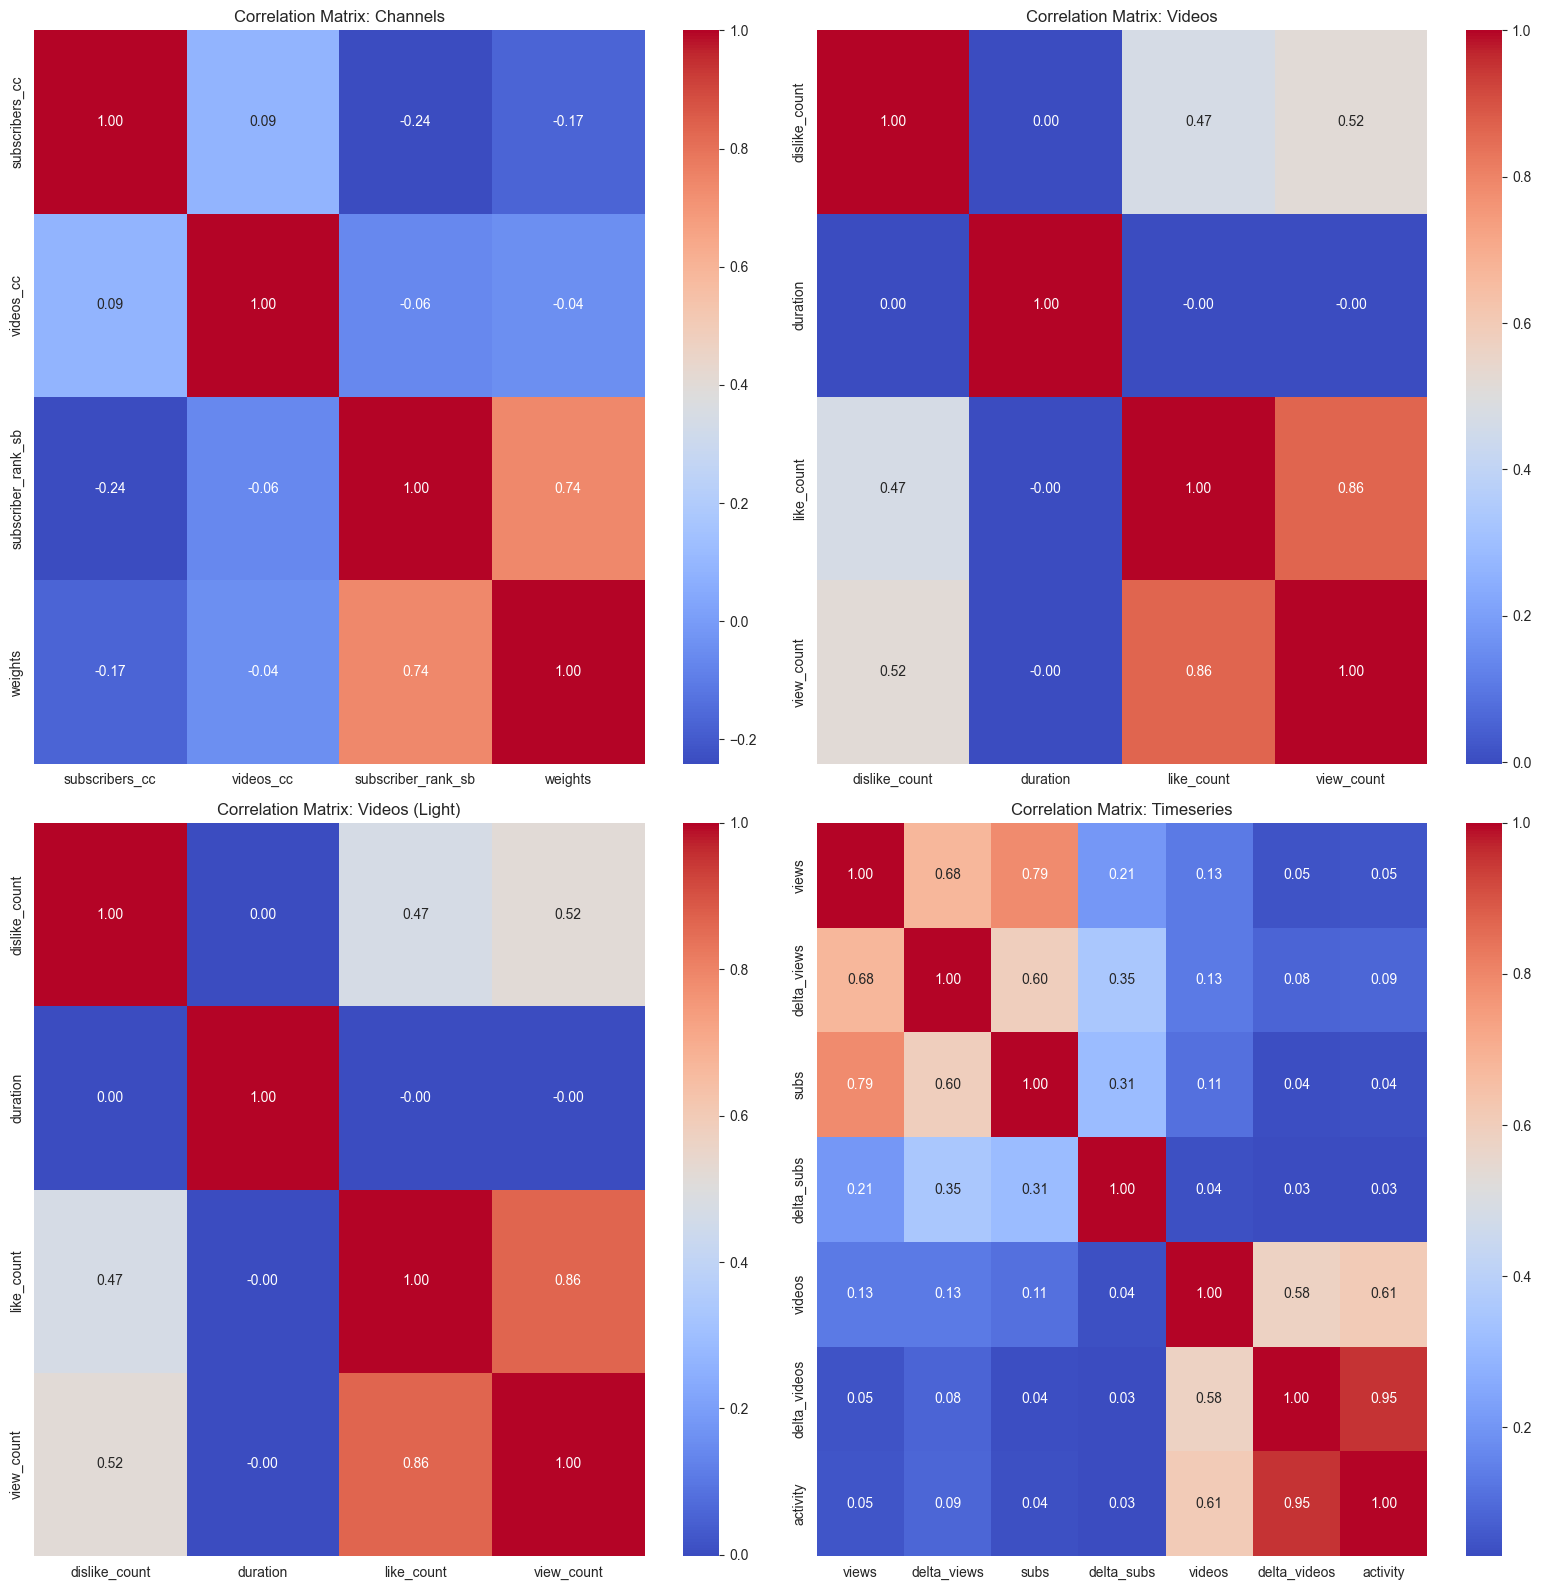

In [8]:
# Filter out the 'Num Comments' dataframe
filtered_df_list = [df for df, name in zip(
    df_list, names) if name != "Num Comments"]
filtered_names = [name for name in names if name != "Num Comments"]

fig = plot_correlation_matrices(filtered_df_list, filtered_names)
plt.show()


First glance insights:
- Channel-level correlations are weak, more uploads don’t clearly relate to more subscribers or better ranks.
- Video-level metrics (views, likes, dislikes) are tightly linked, while duration shows no clear impact on engagement.
- In time-series data, views and subscribers grow together but with only moderate alignment in their weekly changes.

 We note that this subset was not randomly sampled, so correlations are preliminary and may not reflect the global population.

### III. Decisions on Data Preprocessing

Because the dataset is large, we process the data and save the results in Parquet format.
This format allows for faster access and supports iterative reading, which solves the issue of not being able to load everything into memory at once.
The following steps are taken in align with the project goals, code is located in `src/data/preprocessing.py`

#### Cleaning & Storage
We perform standard cleaning for each dataset — removing duplicates, normalizing types and formats, and parsing dates.

Additionally, we created a new lightweight dataset `tags_processed.parquet`, containing only `channel_id`, `display_id`, `tags`, and `upload_date`.
This dataset will be used later in Research Question 2 to cluster different YouTube categories, and was separated to allow faster processing without reloading the large video metadata file.


##### Feature Engineering
Feature engineering is a key part of our pipeline, as these variables are later reused across multiple analyses.
Bellow are some of the most important ones:

- **Engagement Efficiency (video level)**
  For each video *v*:
  $$
  E_v = \frac{\text{likes}_v + \text{dislikes}_v + \text{comments}_v}{\text{views}_v}
  $$
  This score is used for detecting outperformers, and since it is reused a lot, we decided to include it in our saved processed datasets.

<br>

In `time_series.data`, <br>
we align all events to weekly periods (W-MON) and aggregate per channel:
- `reactions_week = Σ(likes + dislikes + comments)`
- `views_week = Σ(views)`

We then compute:
- **Weekly Efficiency**
$$
E_{\text{week}} = \frac{\text{reactionsWeek}}{\text{viewsWeek}}
$$
- **4-Week Trailing Efficiency**
  A rolling version for smoother trends in the `timeseries` dataset.


- **Channel Aggregates (from processed videos)**
  - `avg_engagement_efficiency` — mean efficiency across all channel videos
  - `total_views`, `total_like_count`, `total_dislike_count`, `total_num_comms` — cumulative metrics
  - `avg_video_like_ratio`, `video_count_processed` — engagement and volume indicators
  - `channel_age_days`, `videos_per_day` — activity and lifespan measures

All processed datasets are saved under `/data/processed/` for efficient downstream use.

## 2. Loading the data


### I. Run the preprocessing pipeline

By running the preprocessing pipeline, it takes each dataset from the `data/raw` folder, preprocesses them and saves them in `data/processed` for later use. Before running the function, please make sure you have the python libraries in `requirements.txt` installed, and you have the original datasets in the `raw` folder.

Depending on the machine, this process can take from 30 minutes to a couple of hours.


In [3]:
apply_data_processing()

STEP 1: Processing num_comments
✓ Saved processed num_comments to C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\processed\num_comments_processed.parquet
  Shape: (72924794, 2)

STEP 3: Processing video_light (feather)
Processing video_light in chunks of 20 million rows...
Total record batches in file: 1,113
Processing in chunks...

Processing chunk 1 (20,054,016 rows)...
  ✓ Chunk 1 processed: 20,054,016 rows
Processing chunk 2 (20,054,016 rows)...
  ✓ Chunk 2 processed: 20,054,016 rows
Processing chunk 3 (20,054,016 rows)...
  ✓ Chunk 3 processed: 20,054,016 rows
Processing chunk 4 (12,762,746 rows)...
  ✓ Chunk 4 processed: 12,762,746 rows

✓ Saved processed video_light to C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\processed\videos_light_processed.parquet
  Total rows processed: 72,924,794

STEP 4: Processing channels
Aggregating video statistics from processed videos...


Processing video chunks: |          | 8/? [04:23<00:00]


✓ Saved processed channels to C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\processed\channels_processed.parquet
  Shape: (136470, 18)

STEP 5: Processing timeseries with efficiency metrics
Cleaning timeseries data...
Aligning timeseries to weekly periods...
✓ Timeseries cleaned. Shape: (18872499, 11)
Streaming videos_light from: C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\processed\videos_light_processed.parquet


Processing video batches: |          | 19/? [03:11<00:00]


✓ Processed 19 batches. Total channel-weeks: 15,633,036
Building weekly aggregates DataFrame...
✓ Weekly DataFrame: 15,633,036 rows, 136,470 channels
Computing 4-week trailing efficiency metrics...
✓ Efficiency computed. Shape: (15633036, 4)
Merging efficiency metrics into timeseries...
✓ Merge complete. Final shape: (18872499, 13)
✓ Saved processed timeseries to C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\processed\timeseries_processed.parquet
  Shape: (18872499, 13)

STEP 2: Processing video_metadata (full + tags)
  This may take ~30 minutes due to large file size...
Processing video_metadata in chunks (this may take ~30 minutes)


Processing video metadata chunks: |          | 98/? [47:43<00:00]


✓ Saved processed video_metadata to C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\processed\videos_metadata_processed.parquet
✓ Saved processed tags to C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\processed\tags_processed.parquet
  Total rows processed: 72,924,794
  Total chunks: 98

DATA PROCESSING COMPLETE!
All processed files saved to: C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\processed
Processed files:
  - C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\processed\num_comments_processed.parquet
  - C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\processed\videos_metadata_processed.parquet
  - C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\processed\tags_processed.parquet
  - C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\processed\videos_light_processed.parquet
  - C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\processed\channels_processed.par

{'num_comments': 'C:\\Users\\Jon\\Desktop\\ADA Project2\\ada-2025-project-in5ight\\data\\processed\\num_comments_processed.parquet',
 'video_metadata': 'C:\\Users\\Jon\\Desktop\\ADA Project2\\ada-2025-project-in5ight\\data\\processed\\videos_metadata_processed.parquet',
 'tags': 'C:\\Users\\Jon\\Desktop\\ADA Project2\\ada-2025-project-in5ight\\data\\processed\\tags_processed.parquet',
 'videos_light': 'C:\\Users\\Jon\\Desktop\\ADA Project2\\ada-2025-project-in5ight\\data\\processed\\videos_light_processed.parquet',
 'channels': 'C:\\Users\\Jon\\Desktop\\ADA Project2\\ada-2025-project-in5ight\\data\\processed\\channels_processed.parquet',
 'timeseries': 'C:\\Users\\Jon\\Desktop\\ADA Project2\\ada-2025-project-in5ight\\data\\processed\\timeseries_processed.parquet'}

### II. Checking the processed data

In [21]:
channel_df = pd.read_parquet(DATASET_CHANNELS)
channel_df.head(6)

,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed
0,Gaming,2010-04-29,UC-lHJZR3Gqxm24_Vd_AJ5Yw,PewDiePie,101000000,3956,3.0,2.087,3468.0,1.140715,0.041988,2.345148e+10,3449869.0,950538161.0,24615813.0,72904068.0,0.982724,3927
1,Education,2006-09-01,UCbCmjCuTUZos6Inko4u57UQ,Cocomelon - Nursery ...,60100000,458,7.0,2.087,4804.0,0.095337,0.002954,4.323417e+10,519007.0,96951076.0,55216214.0,611177.0,0.633412,462
2,Entertainment,2006-09-20,UCpEhnqL0y41EpW2TvWAHD7Q,SET India,56018869,32661,8.0,2.087,4785.0,6.825705,0.004994,4.075935e+10,30501034.0,139097733.0,21976958.0,5557559.0,0.859855,23903
3,Howto & Style,2016-11-15,UC295-Dw_tDNtZXFeAPAW6Aw,5-Minute Crafts,60600000,3591,9.0,2.087,1076.0,3.337361,0.011340,1.596080e+10,3383229.0,109974549.0,13606395.0,4506589.0,0.904908,3624
4,Sports,2007-05-11,UCJ5v_MCY6GNUBTO8-D3XoAg,WWE,48400000,43421,11.0,2.087,4552.0,9.538884,0.015842,3.624948e+10,7868933.0,330247613.0,18966387.0,19107723.0,0.932584,40549
5,Entertainment,2007-01-15,UCIwFjwMjI0y7PDBVEO9-bkQ,Justin Bieber,46574085,134,12.0,2.087,4668.0,0.028706,0.025269,5.886436e+08,17697.0,8815774.0,373636.0,719646.0,0.949962,128


In [26]:
timeseries_df = pd.read_parquet(DATASET_TIMESERIES)
timeseries_df.head(5)

,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,week_start,efficiency_4week,efficiency_4week_filled
0,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-01,62524.500,4113.500,1466.000,0.000,29,0,1,2016-07-26,0.049820,0.049820
1,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-08,67600.250,5075.750,1508.625,42.625,30,1,2,2016-08-02,0.049374,0.049374
2,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-15,69982.000,2381.750,1530.750,22.125,31,1,2,2016-08-09,0.045413,0.045413
3,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-22,72663.125,2681.125,1558.625,27.875,32,1,2,2016-08-16,0.046415,0.046415
4,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-29,75093.000,2429.875,1591.000,32.375,33,1,2,2016-08-23,0.031169,0.031169


In [13]:
timeseries_df.columns

Index(['channel', 'category', 'datetime', 'views', 'delta_views', 'subs',
       'delta_subs', 'videos', 'delta_videos', 'activity', 'week_start',
       'efficiency_4week', 'efficiency_4week_filled'],
      dtype='object')

Datasets that are too large to fit in memory at once like `videos_metadata_processed.parquet`, `videos_light_processed.parquet` and `tags_processed.parquet`, we process iteratively, meaning, we read it by chunks. This ensures that we can use these datasets in our Research Questions and proves feasibility.

_The larger 20GB `videos_metadata_processed.parquet` takes around 30 minutes in our local machines._


In [23]:
# Example of reading from videos_light_processed.parquet with chunks
for df_chunk in iterate_parquet_stream(DATASET_VIDEO_LIGHT, window_size=20_000_000):
    print(df_chunk.shape)

(20054016, 11)
++ Chunk 000: rows 0-20,054,016 | total=20,054,016
(20054016, 11)
++ Chunk 001: rows 20,054,016-40,108,032 | total=40,108,032
(20054016, 11)
++ Chunk 002: rows 40,108,032-60,162,048 | total=60,162,048
(12762746, 11)
++ Final chunk: rows 60,162,048-EOF | rows=12,762,746


# 3. Basic information about the data

### I. Subscribers distribution

As our research is focused on working with small- to midsize-channels, it is important to understand overall image of subscribers count.

In [41]:
# Compute weighted 50th (median) and 90th percentiles of subscriber counts
channel_df =  pd.read_parquet(DATASET_CHANNELS)
cuts = weighted_percentiles(
    channel_df["subscribers_cc"],
    channel_df["weights"],
    percentiles=(50, 90)
)
print(cuts)
p50, p90 = cuts[50], cuts[90]

{50: np.float64(22200.0), 90: np.float64(160000.0)}


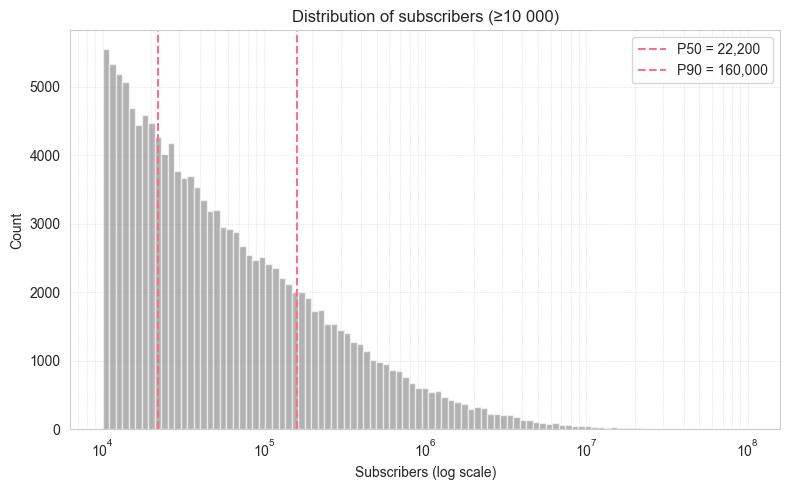

In [23]:
plot_log_histogram(
    channel_df,
    column_name="subscribers_cc",
    percentile_markers={"P50": p50, "P90": p90},
    bins=np.logspace(4, 8, 100),
    plot_title="Distribution of subscribers (≥10 000)",
    x_axis_label="Subscribers (log scale)"
)
plt.show()

The distribution is highly right-skewed (heavy-tailed), most channels cluster near the lower end (10 k – 100 k), and very few extend into the millions.

### II. Average Efficiency by category

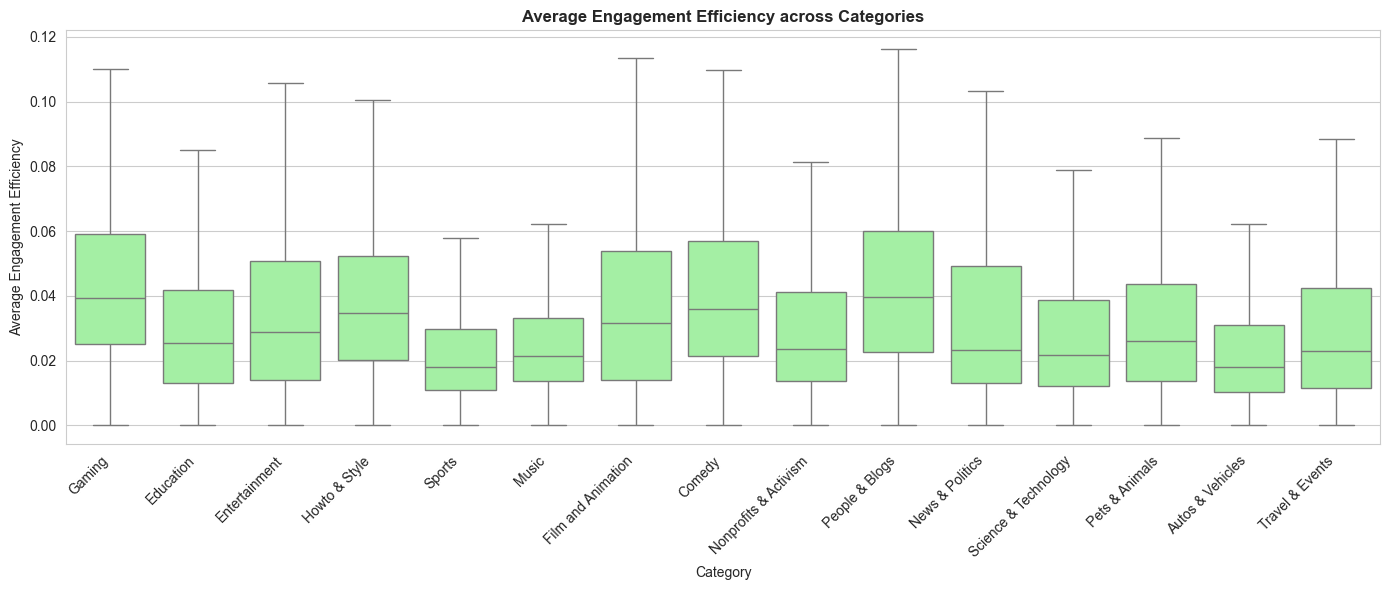

In [24]:
plt.figure(figsize=(14, 6))
sns.boxplot(
    data=channel_df,
    x="category_cc",
    y="avg_engagement_efficiency",
    color="palegreen",
    showfliers=False
)
plt.title("Average Engagement Efficiency across Categories", weight="bold")
plt.xlabel("Category")
plt.ylabel("Average Engagement Efficiency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

This indicates that content type strongly influences how actively viewers engage with creators.

### III. Efficiency overtime

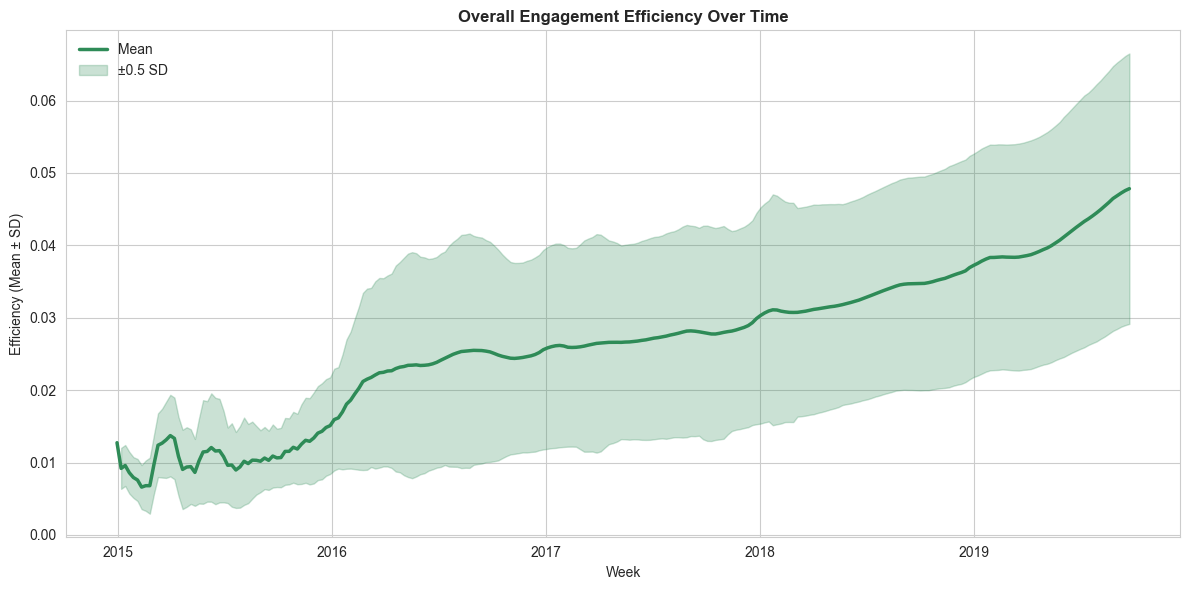

In [27]:
plot_timeseries_trend(
    df=timeseries_df,
    date_col="week_start",
    value_col="efficiency_4week_filled",
    title="Overall Engagement Efficiency Over Time",
    xlabel="Week",
    ylabel="Efficiency (Mean ± SD)",
    smooth=True,
    window=6,
    color="seagreen"
)

The time series shows a clear upward trend in overall engagement efficiency from 2015 to 2019.
This indicates that over time, viewers have become increasingly active in leaving likes, dislikes, and comments relative to the number of views.

# 4. Detecting Outperformers - Research Queston 1

### I. Identifying small to mid sized channels

We define our focus cohort as channels with 10 000–100 000 subscribers. The subscriber distribution is heavy-tailed: the median (P50) is ≈ 22 k and P90 is ≈ 160 k, so 100 k lies well below the top decile while meaningfully above the median. We use 100 k because it:
- aligns with YouTube’s Silver Creator milestone,
- avoids dominance by a small set of very large channels and
 - provides a large, comparable sample of growing creators.

In [29]:
small_mid_sized_channels_df = channel_df[channel_df["subscribers_cc"] < 100_000].copy()

### II. Fitting the Model and Detecting the Outperformers

Outperformers are defined as small- to mid-sized channels that achieve an engagement efficiency substantially higher than what is expected for their subscriber size and category, after controlling for the heavy-tailed scaling of engagement on YouTube.

Starting from the efficiency metric that we defined in feature engineering, we continue with:

- **Expected Efficiency Model (Log–Log Linear Regression)**

  To understand how efficiency scales with channel size, we fit a log–log regression:
  $$
  \log_{10}(E_c) = a + b \, \log_{10}(\text{subscribers}_c) + \varepsilon_c
  $$
  Using logs stabilizes the heavy-tailed data and makes the relationship approximately linear.
  This model captures the power-law scaling between engagement and audience size, allowing us to identify channels whose efficiency significantly exceeds the expected baseline for their size.

- **Residual Efficiency (Deviation from Expectation)**

  The residual measures how much a channel over- or under-performs relative to its expected efficiency:
  $$
  r_c = \log_{10}(E_c) - \big(a + b \, \log_{10}(\text{subscribers}_c)\big)
  $$

- **Quiet Outperformers**

  Channels with residuals above a threshold \( \gamma \) (e.g., mean + 2·std or the top 5%) are labeled as outperformers:
  $$
  r_c > \gamma \;\Rightarrow\; \text{quiet outperformer}
  $$

In [30]:
channels_model = linear_log_log_model(
    df=small_mid_sized_channels_df,
    x_col="subscribers_cc",
    y_col="avg_engagement_efficiency",
    weight_col="weights",
    log_base=10,
    verbose=True,
)

channels_model.head(5)

log–log model fitted: log(y) = -0.9058 + -0.1419 * log(x)


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,...,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,log_x,log_y,pred_log_y,residual,zscore
25085,People & Blogs,2016-07-04,UC7wnYvoFWmX-Ad6Az7BsiDQ,NinaUnrated VLOGS,98200,22,78696.0,3.6480,1210.0,0.018182,...,174949.0,2266.0,29914.0,0.986781,16,4.992111,-1.164280,-1.613989,0.449709,1.233636
26369,Music,2018-05-13,UCCjlZHOg6TWQmJ4k3esGxCg,Kevser Öz,92300,264,83140.0,4.2195,532.0,0.496241,...,216481.0,19153.0,13512.0,0.978910,267,4.965202,-1.488122,-1.610172,0.122050,0.341271
26531,People & Blogs,2010-09-08,UC5H8PC7IVxeicx5x5p8roWA,Casi Davis,98683,32,84226.0,4.3250,3336.0,0.009592,...,199670.0,5360.0,8565.0,0.965106,35,4.994242,-1.531054,-1.614292,0.083238,0.235570
26730,People & Blogs,2018-05-02,UCDGY6cFaZKjlY1bguFZHdeQ,Nidal Wonder,98202,45,85347.0,4.4395,543.0,0.082873,...,299536.0,13301.0,12879.0,0.970602,52,4.992120,-1.529482,-1.613991,0.084508,0.239030
26751,Film and Animation,2011-07-30,UC5du0zGwGLWhMAJkLmltGpg,iCraft,92800,69,85414.0,4.4265,3011.0,0.022916,...,232189.0,17840.0,2423.0,0.899380,70,4.967548,-1.824856,-1.610505,-0.214352,-0.574900


The residual distribution is approximately bell-shaped but slightly right-skewed, reflecting that most channels perform near their expected efficiency while a small subset achieve substantially higher engagement relative to size.
We define outperformers as those above the 97th percentile, representing the top 3% of channels with the largest positive deviations.
This stricter cutoff filters out statistical noise and highlights genuinely exceptional channels whose audience engagement is consistently beyond what their subscriber base would predict.

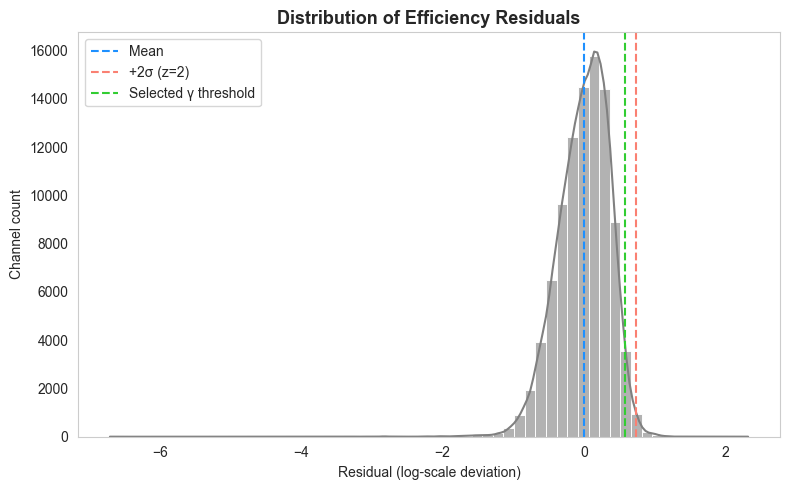

In [31]:
gamma = np.percentile(channels_model["residual"], 97)
plot_residual_distribution(channels_model["residual"], threshold_gamma=gamma)

In [42]:
is_outperformer_mask = channels_model["residual"] > gamma
channel_df["is_outperformer"] = is_outperformer_mask.reindex(channel_df.index, fill_value=False)

In [44]:
outperformers_df = channel_df[channel_df['is_outperformer']]
non_outperformers_df = channel_df[~channel_df['is_outperformer']]
print(len(outperformers_df))
outperformers_df.head(6)

2831


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,is_outperformer
27568,Music,2012-06-17,UCGnEWsLelLFqMkWcb8s7-nA,孤独なghost,93200,121,88557.0,3.9875,2688.0,0.045015,0.105720,9817455.0,25500.0,845110.0,3881.0,10345.0,0.996371,125,True
29460,People & Blogs,2016-11-05,UCwpAYjmPdYVw6ZNoiul8g2Q,Muhammad Arbaz Offic...,84050,175,95847.0,3.7155,1086.0,0.161142,0.161395,4066492.0,68508.0,303546.0,20696.0,65870.0,0.968095,181,True
30591,Gaming,2019-01-16,UCrDEwtROpcijOFP9uMwz19Q,Parallel Samzyy,79100,40,99714.0,3.7395,284.0,0.140845,0.098866,6788720.0,9521.0,604033.0,11725.0,10072.0,0.979401,51,True
32883,Pets & Animals,2015-12-16,UCkrkMMAyxC9vGNa6ZJYyscg,Takis Shelter - The ...,73600,316,109765.0,5.0415,1411.0,0.223955,0.151517,22679099.0,91716.0,1207584.0,9496.0,104127.0,0.995255,340,True
32943,Gaming,2011-09-27,UC3-8qZ-rZvlSVWwkHoeelCA,TheMythicalSausage,83000,1766,110160.0,5.0940,2952.0,0.598238,0.094543,12100847.0,3513327.0,416318.0,7942.0,87631.0,0.977471,1773,True
33055,Gaming,2019-04-17,UCaH2302aYnmOJH-CWn-Bebg,Military Dave,84100,52,110730.0,4.9860,193.0,0.269430,0.110061,2810462.0,21462.0,304313.0,17771.0,30004.0,0.864303,55,True


#### III. Categories of quiet outperformers

Initially, dataset provides us a correspondence of each channel to 1 of 15 predefined categories. Let's see, how quiet outperformers are distributed by those categories and how they relate to overall distribution of categories among all channels.

_Note: those categories can be then upgraded by using some additional metadata about videos, such as tags or description data. We explore this on Research Question 2._

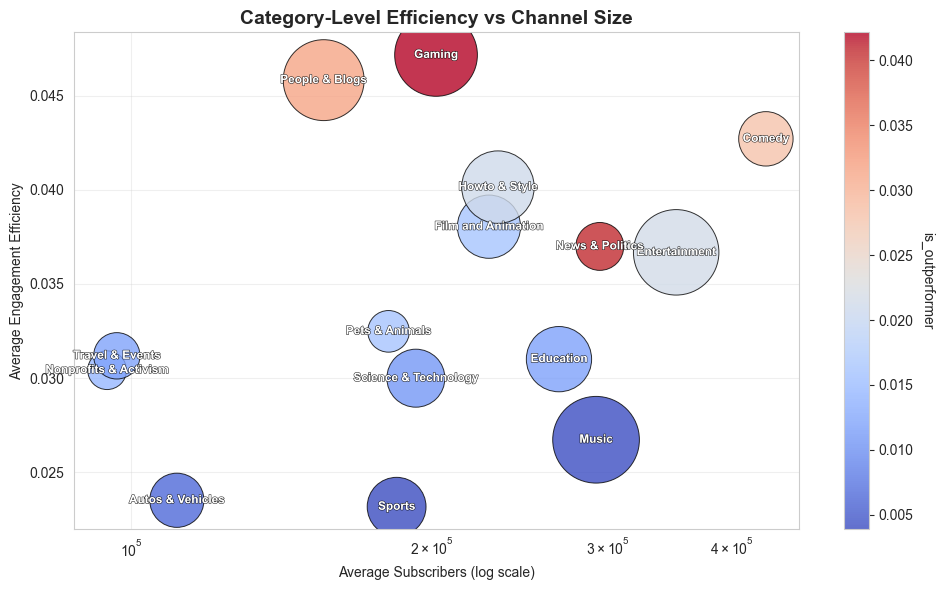

In [45]:
plot_category_bubble(
    dataframe=channel_df,
    size_column="subscribers_cc",
    value_column="avg_engagement_efficiency",
    category_column="category_cc",
    color_column="is_outperformer",  # average will give share of outperformers
    plot_title="Category-Level Efficiency vs Channel Size",
    x_axis_label="Average Subscribers (log scale)",
    y_axis_label="Average Engagement Efficiency",
)

#### IV. Diving into one Outperformer

Let’s take a closer look at one of the top quiet outperformers, the channel “Gym Monk / Gaming.”
This channel still exists today with around 28K subscribers, and during the 2019 period it had multiple videos reaching hundreds of thousands of views.

In [86]:
# Loading the time series data
timeseries_df = pd.read_parquet(DATASET_TIMESERIES)

In [17]:
channel = 'UCfs20O_RuLJXGGTxv5VIzdw'
channel_timeseries = timeseries_df[timeseries_df['channel'] == channel]
channel_timeseries.head(5)

,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,week_start,efficiency_4week,efficiency_4week_filled
12899150,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-04-25,26360.750,63.750,1775.750,0.000,77,0,11,2016-04-19,1.208036,1.208036
12899151,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-02,26807.000,446.250,1795.000,19.250,77,0,6,2016-04-26,NaN,NaN
12899152,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-09,27071.250,264.250,1806.375,11.375,78,1,1,2016-05-03,1.193830,1.193830
12899153,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-16,27407.500,336.250,1814.750,8.375,80,2,3,2016-05-10,1.154780,1.154780
12899154,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-23,28045.125,637.625,1830.125,15.375,84,4,6,2016-05-17,0.880374,0.880374


Let's compare his efficiency(outperformer) to someone who is in the same category "Gaming" and has an average efficiency.


In [31]:
target_channel = "UCfs20O_RuLJXGGTxv5VIzdw"
target_eff = channel_df.loc[channel_df["channel"] == target_channel, "avg_engagement_efficiency"].iloc[0]

# Find average efficiency for Gaming category
avg_eff_gaming = (
    channel_df.loc[channel_df["category_cc"] == "Gaming", "avg_engagement_efficiency"]
    .mean()
)

# Find channel in Gaming closest to that average
avg_channel = (
    channel_df[channel_df["category_cc"] == "Gaming"]
    .assign(diff=lambda x: (x["avg_engagement_efficiency"] - avg_eff_gaming).abs())
    .sort_values("diff")
    .iloc[0]
)

avg_channel_id = avg_channel["channel"]
avg_channel_eff = avg_channel["avg_engagement_efficiency"]

print(f"Matched 'average' Gaming channel: {avg_channel_id}")

Matched 'average' Gaming channel: UCRZ5-H-PV_2jsj3JsB9uU2A


In [34]:
channel_2 = 'UCRZ5-H-PV_2jsj3JsB9uU2A'
channel_timeseries_2 = timeseries_df[timeseries_df['channel'] == channel_2]
channel_timeseries_2.head(5)

,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,week_start,efficiency_4week,efficiency_4week_filled
8395116,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-02,178813.500,751.500,831.000,0.000,5,0,0,2016-04-26,NaN,NaN
8395117,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-09,180609.500,1796.000,837.750,6.750,5,0,0,2016-05-03,NaN,NaN
8395118,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-16,182562.375,1952.875,845.125,7.375,6,1,1,2016-05-10,0.012577,0.012577
8395119,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-23,184819.000,2256.625,860.000,14.875,7,1,2,2016-05-17,0.010054,0.010054
8395120,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-30,186508.625,1689.625,867.000,7.000,8,1,2,2016-05-24,0.015791,0.015791


H₀ (null hypothesis):
The outperformer’s engagement efficiency over time is not significantly different from that of an average Gaming channel.

H₁ (alternative hypothesis):
The outperformer’s engagement efficiency is significantly higher than that of an average Gaming channel.

In [42]:
target_ts = timeseries_df.loc[timeseries_df["channel"] == target_channel].copy()
avg_ts = timeseries_df.loc[timeseries_df["channel"] == avg_channel].copy()

# Drop missing values
eff_out = target_ts["efficiency_4week_filled"].dropna()
eff_avg = avg_ts["efficiency_4week_filled"].dropna()

# Mann-Whitney U test (one-sided: outperformer > average)
stat, p_value = mannwhitneyu(eff_out, eff_avg, alternative="greater")

print(f"Mann–Whitney U statistic: {stat:.3f}")
print(f"p-value: {p_value:.6f}")

Mann–Whitney U statistic: 7840.000
p-value: 0.000000


To assess whether the outperformer’s engagement efficiency is statistically higher than that of a typical Gaming channel, we performed a one-sided Mann–Whitney U test on their weekly efficiency distributions.
The test yielded a U statistic of 7840 and a p-value < 0.000001, allowing us to reject the null hypothesis of equal engagement levels.
This confirms that the outperformer’s audience interacts significantly more per view than viewers of a comparable average Gaming channel.

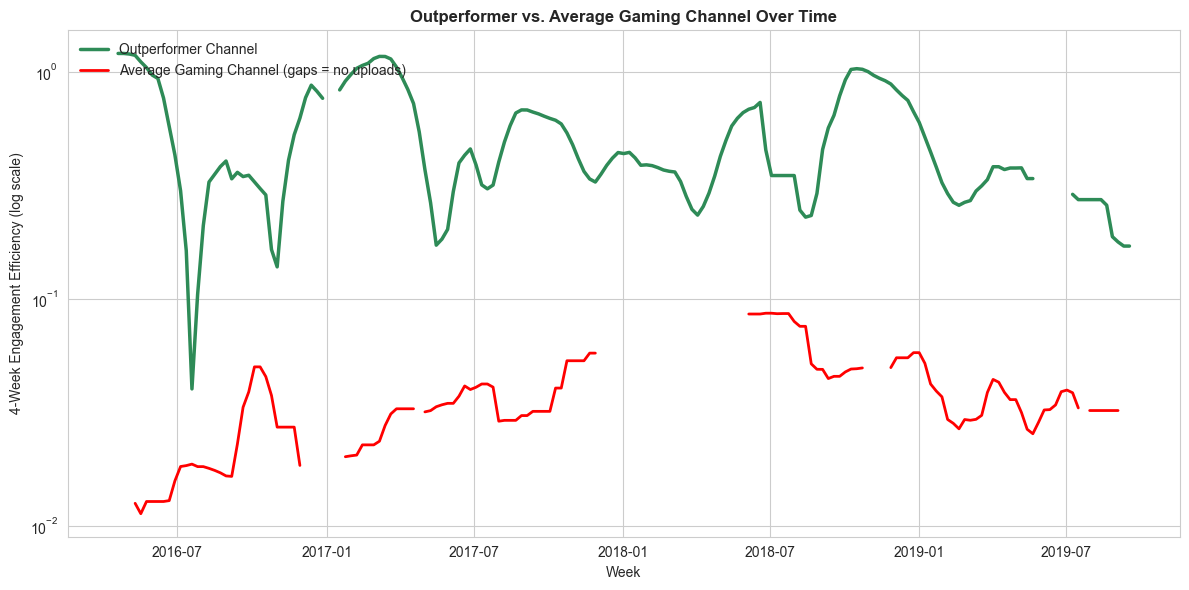

In [40]:
plot_channel_comparison(
    df=timeseries_df,
    target_channel=target_channel,
    avg_channel_id=avg_channel_id,
)

As expected, the outperformer channel achieves consistently higher engagement efficiency than the average Gaming channel throughout the observed period.
Additionally, the outperformer shows fewer and shorter inactivity gaps, indicating a more consistent upload pattern and sustained audience engagement over time.


These observations motivate our subsequent research questions. Having established that a quiet outperformer achieves consistently higher engagement efficiency and more stable activity than a comparable average Gaming channel, we next ask whether this pattern generalizes across the platform. Specifically, we investigate how quiet outperformers are distributed across content communities (RQ2), which structural or strategic choices, such as posting frequency, duration, or timing, are statistically associated with higher efficiency within each size tier and content type (RQ3), and finally, whether quiet outperformers sustain more stable growth in views and subscribers compared to similar non-outperforming channels (RQ4). Together, these questions aim to uncover the structural and behavioral factors that differentiate quiet outperformers from typical creators beyond raw engagement metrics.

## 5. Mathematical model of Research Questions

This section presents the detailed methods proposed for each research question.

### RQ2: Are quiet outperformers concentrated in particular content categories, or do their engagement efficiency patterns vary across categories?

---

#### 1. Choice of Content Categorization

We consider two approaches to define a channel's content category: (a) Using YouTube's 15 official categories, (b) Using data-driven clusters
To better capture real content communities, we construct data-driven clusters from video-level textual data (tags).

This approach is feasible in our setting with the new lightweight dataset (tags_processed.parquet) containing only channel_id, display_id, tags, and upload_date (reducing the original metadata file from 13 GB to 5 GB). Also instead of loading the entire dataset at once, we can iterate through it in manageable chunks using the iterate_parquet_stream function we built in the data loader.

#### 2. Building Data-Driven Content Clusters

##### 2.1 Text Preprocessing
For each video:
1. Clean tags text:
   - lowercase
   - remove punctuation, stopwords, and numbers
   - lemmatize or stem words
2. Join all tags into one document string per video.


##### 2.2 Text Representation
We represent each video's tags as a mixture of latent topics using **Latent Dirichlet Allocation (LDA)**, a probabilistic topic modeling approach.

We considered to use transformer embeddings (e.g., Sentence-BERT) and density-based clustering (HDBSCAN), which captures semantic similarity more effectively than LDA but is computationally expensive for millions of short tag strings and sensitive to parameter tuning. So we decided to use LDA.


LDA assumes that:
- each video's tag set is generated from a mixture of *K* latent topics, and
- each topic is a probability distribution over words.

Formally, for each video *v* (treated as a “document” of tags):

$$
\theta_v \sim \text{Dirichlet}(\alpha), \quad \phi_k \sim \text{Dirichlet}(\beta)
$$

where
- $\theta_v = (\theta_{v1}, \theta_{v2}, ..., \theta_{vK})$ represents the topic proportions for video *v*,
- $\phi_k$ is the word distribution for topic *k*,
- $\alpha$ and $\beta$ are Dirichlet hyperparameters controlling sparsity.

Each tag $w_{vn}$ in video *v* is generated by:
$$
z_{vn} \sim \text{Multinomial}(\theta_v), \quad w_{vn} \sim \text{Multinomial}(\phi_{z_{vn}})
$$

After fitting the model, each video is represented by its topic distribution vector:

$$
\theta_v = (\theta_{v1}, \theta_{v2}, ..., \theta_{vK}), \quad \sum_{k=1}^{K} \theta_{vk} = 1
$$

We determine the optimal number of topics *K* using **topic coherence** and **perplexity** metrics.
- Higher coherence indicates more interpretable and distinct topics.
- Lower perplexity indicates better generalization to unseen data.

Each topic is then characterized by its most probable words, and then summarized using a large language model (LLM) for interpretability.

Once trained, we assign each video to its dominant topic:
$$
\text{Topic}(v) = \arg\max_k \theta_{vk}
$$

These inferred topics form data-driven content categories, which are later aggregated to the channel level (next step).

#### 3. Aggregating Clusters to the Channel Level

Because quiet outperformers are defined at the channel level, we aggregate the video clusters as follows:

1. Count the number of videos per cluster for each channel:

    $$
    n_{c,k} = \mathrm{\#\ of\ videos\ from\ channel\ } c \mathrm{\ in\ cluster\ } k
    $$

2. Compute each channel's cluster proportion:

    $$
    p_{c,k} = \frac{n_{c,k}}{\sum_{j} n_{c,j}}
    $$

3. Assign the dominant cluster:

    $$
    \text{Cluster}_c = \arg\max_k p_{c,k}
    $$

4. Compute topic diversity using Shannon entropy:

    $$
    H_c = -\sum_k p_{c,k} \log(p_{c,k})
    $$

    Channels with high entropy (e.g., $H_c > 1.5$) can be excluded to focus on thematically consistent creators.

#### 4. Comparing Engagement Efficiency Among Quiet Outperformers Across Categories

Let $\hat{\varepsilon}_c$ denote the *residual efficiency* for channel $c$, derived from RQ1, and let $k$ denote its assigned content category or cluster (from YouTube's predefined categories or LDA-derived topics).

##### 4.1 Summary Statistics and Visualization

For each category $k$, compute descriptive statistics among quiet outperformers:
$$
\text{Mean}_k = \frac{1}{n_k} \sum_{c \in k} \hat{\varepsilon}_c, \quad
\text{Median}_k, \quad \text{IQR}_k, \quad \text{SD}_k
$$

Visualize the efficiency distributions across categories using violin plots, boxplots**, or kernel density plots (KDE).
These visuals reveal whether outperformers from certain content types (e.g., Education, Gaming, Lifestyle) tend to achieve systematically higher engagement efficiency.

##### 4.2 Testing Differences in Efficiency Distributions

To formally test whether efficiency distributions differ across categories, apply the Kruskal-Wallis H test:

$$
H_0: f_1(\hat{\varepsilon}) = f_2(\hat{\varepsilon}) = \dots = f_K(\hat{\varepsilon})
$$

$$
H = \frac{12}{N(N+1)} \sum_{k=1}^{K} n_k (\bar{R}_k - \bar{R})^2
$$

where:
- $n_k$ = number of outperformers in category $k$
- $\bar{R}_k$ = mean rank of efficiency in category $k$
- $\bar{R}$ = mean rank overall
- $N$ = total number of outperformers

If $p < 0.05$, we reject $H_0$ and conclude that at least one content category of outperformers exhibits a distinct engagement efficiency distribution.

If the global test is significant, perform Dunn's post-hoc tests with False Discovery Rate correction to identify which categories differ.


##### 4.3 Concentration of Outperformers Across Categories

To assess whether quiet outperformers are disproportionately represented in certain content types, compare the observed vs. expected counts of outperformers per category using a **Chi-square goodness-of-fit test**:

$$
\chi^2 = \sum_{k=1}^{K} \frac{(O_k - E_k)^2}{E_k}
$$

where:
- $O_k$ = observed number of outperformers in category $k$
- $E_k$ = expected number based on overall category proportions in the full dataset

A significant result ($p < 0.05$) indicates that outperformers are concentrated in specific content categories rather than evenly distributed.



### RQ3: Which structural choices (video duration, posting frequency, posting consistency) are statistically associated with higher efficiency within each size tier?

---




We analyze how structural choices relate to engagement efficiency while removing scale effects and comparing channels within size tiers. Because efficiency co-varies with subscriber count and channels differ by composition, naive comparisons are biased. We address this by (i) residualizing efficiency against size in a log–log baseline, and (ii) estimating within-tier regressions.

#### 1. Outcome Metric: Size-Adjusted Efficiency (Residual)

From the channel efficiency we computed before,

Baseline (size) model:
$$
\log_{10}(E_c) \;=\; a + b\,\log_{10}(\text{subscribers}_c) + \varepsilon_c.
$$

Residual (outcome):
$$
r_c \;=\; \log_{10}(E_c) - \big(a + b\,\log_{10}(\text{subscribers}_c)\big).
$$
Here, $r_c>0$ indicates performance above size-based expectation.

#### 2. Size Tiers

Tiers are defined by subscriber quantiles:
- Small: 0–50th percentile
- Mid: 50–90th percentile

Analyses are run separately within each tier.


#### 3. Structural Predictors (8-week window)

All predictors are backward-looking (no leakage) and summarized at the channel level:

- Posting frequency (pace): median weekly uploads over the prior 8 weeks.
- Posting consistency (0–1):
$$
\text{cons8} \;=\; \mathrm{clip}\!\left(1-\frac{\mathrm{std}_8}{\max(\mathrm{mean}_8,\varepsilon)},\,0,\,1\right),\quad \varepsilon=0.1.
$$
- Video duration: channel median duration; modeled as $\log(\text{duration})$ to reduce skew.

Predictors are z-scored within tier to make coefficients comparable.

#### 4. Estimation and Final Tests

Within each tier, we estimate a **weighted least squares** regression:
$$
r_c \;=\; \beta_0 + \beta_1\,\text{pace8}_c + \beta_2\,\text{cons8}_c + \beta_3\,\log(\text{duration}_c) \, + \, \text{controls (category FE, log age, videos/day, ... )} \, + \, \varepsilon_c.
$$

- Weights: number of videos for the channel (precision weighting of $r_c$).
- Standard errors: HC3 (heteroskedasticity-robust with a leverage adjustment).
- Final tests: two-sided tests of $H_0:\beta_k=0$ for pace, consistency, and duration in each tier.
- Effect sizes: report predicted change in $r_c$ from 25th→75th percentile for each factor with 95% CIs; translate to % on the original scale for readability.

#### 5. Robustness

- Recompute predictors with 4w and 12w windows.
- Duration variants: trimmed mean
- Check pace–consistency collinearity; confirm stability.


**Interpretation.** A positive and significant $\beta_2$ indicates that more consistent posting is associated with higher size-adjusted efficiency within that tier; $\beta_1$ captures frequency beyond consistency; $\beta_3$ summarizes how typical (log) duration relates to efficiency after basic controls.


### RQ4:Do quiet outperformers exhibit more stable and consistent growth in weekly views and subscribers compared to non-outperforming channels with similar characteristics?

---

To answer this question, we compare the long-term growth volatility of two groups: "Outperformers" (treated) and "non-Outperformers" (control). Unlike event-based analyses where treatment occurs at a specific time, our treatment is status-based: channels are classified as outperformers according to their engagement efficiency. Because outperformers are not randomly assigned and tend to differ in characteristics such as size, age, and category, a simple comparison would be biased. This selection bias introduces confounding, which we address using a quasi-causal inference framework based on Propensity Score Matching (PSM).

Due to the complexity of this analysis, it is divided into two Jupyter notebooks that are in the `src/notebooks` folder, that can be consulted for full details. In the next milestone, we will present the complete results and findings.

The notebooks are located here:
- `src/notebooks/sustainability_test_channel.ipynb`
- `src/notebooks/sustainability_outperformers_vs_control.ipynb`


#### 1. Outcome Metric: Growth Volatility (Coefficient of Variation)

To quantify growth stability, we first define growth volatility as the **Coefficient of Variation (CV)**. This metric is calculated over a 12-month (52-week) window for each channel's weekly change in views ($\Delta \text{Views}$) and subscribers ($\Delta \text{Subs}$). This specific subset was chosen for computational feasibility and practical relevance, allowing for robust conclusions to be drawn from the most recent yearly data. This confirmed that the data size was manageable and allowed us to isolate a high-quality subset for analysis.

The CV is the ratio of the standard deviation ($\sigma$) to the mean ($\mu$) of this weekly growth:

$$
\text{CV} = \frac{\sigma_{\text{growth}}}{\mu_{\text{growth}}}
$$

The CV is a crucial metric for this analysis because it is scale-independent. It normalizes volatility relative to the channel's average growth, allowing for a fair comparison between channels of vastly different sizes (e.g., a channel with 10k subscribers vs. one with 10M). A lower CV indicates lower volatility and thus higher sustainability.


#### 2. Causal Methodology: Propensity Score Matching (PSM)

We use **Propensity Score Matching (PSM)** to create a synthetic control group that is statistically similar to the treated group across all observed covariates ($X$). This allows us to estimate the causal effect of being an Outperformer on growth volatility, isolating it from confounding factors like channel size or age.

The methodology relies on the propensity score, $e(X)$, which is the conditional probability of a channel being in the treated group (Outperformer) given its pre-treatment covariates $X$:

$$
e(X) = P(\text{is\_outperformer} = 1 \mid X)
$$

#### 3. Propensity Score Model

We estimate the propensity score $e(X)$ using a **Logistic Regression** model.

##### 3.1 Model Covariates and Transformations
The model predicts the treatment (`is_outperformer`) based on a set of key confounding variables:

$$
\text{logit}(e(X)) = \beta_0 + \beta_1 \cdot \log(\text{channel\_age\_days}) + \beta_2 \cdot \log(\text{videos\_cc}) + \dots
$$

* **Logarithmic Transformation**: Covariates such as `subscribers_cc`, `channel_age_days`, and `videos_cc` are heavily right-skewed. We apply a $\text{log()}$ transformation to these features. This compresses the scale, mitigates the influence of extreme outliers, and better approximates the linear relationship assumed by the logistic regression's logit link function.

* **Non-Linear Terms**: To improve model fit, we may introduce quadratic terms (e.g., \( I([\log(\text{subscribers\_cc})]^2) \)). This allows the model to capture non-linear relationships.


* **Regularization**: To stabilize the model coefficients against outliers and prevent overfitting, we apply $\mathbf{L2\ regularization}$ (Ridge regression) during the model fitting process.

#### 4. Matching Process and Balance Check

After estimating propensity scores for all channels, we perform 1:1 nearest-neighbor matching to create a balanced dataset.

* **Exact Matching**: We enforce exact matching on the `category_cc` variable. This ensures that a treated "Gaming" channel is only ever matched with a control "Gaming" channel, eliminating bias from content category differences.

* **Caliper Matching**: We impose an extremely tight caliper (e.g., $0.0005$). This means a match is only considered valid if the absolute difference in propensity scores between the treated and control unit is less than this caliper value, ensuring only highly similar channels are paired.

##### Standardized Mean Difference (SMD)
To verify the success of the matching process, we assess covariate balance using the Standardized Mean Difference (SMD). The SMD measures the difference in means between the treated and control groups in units of pooled standard deviation:

$$
\text{SMD} = \frac{\bar{X}_{\text{Treated}} - \bar{X}_{\text{Control}}}{\sqrt{\frac{S_{\text{Treated}}^2 + S_{\text{Control}}^2}{2}}}
$$

SMD is a critical diagnostic. Before matching, a large SMD ($|\text{SMD}| > 0.1$) indicates imbalance and justifies the need for matching. After matching, we require $|\text{SMD}| < 0.1$ for all covariates to confirm that the groups are statistically comparable and selection bias has been minimized.


#### 5. Final Statistical Test

The final step is to compare the outcome (CV) between the newly balanced treated and control groups.

* **Mann-Whitney U Test**: Visual inspection (histograms, Q-Q plots) and formal tests (e.g., Shapiro-Wilk) confirm that the CV metrics are not normally distributed. Therefore, we use the Mann-Whitney U test, a non-parametric equivalent of the t-test. This test ranks the data and compares the median of the two groups, allowing us to reliably test the hypothesis that Outperformers and Control channels have different median growth volatility without violating distributional assumptions.